# Residual Network for Fashion-MNIST with a Custom Training Loop

*A ResNet-style classifier built with custom layers and the Keras model subclassing API, trained with a hand-written training loop in TensorFlow 2.*

The goal of this project is to use the model subclassing API together with custom layers to build a residual network architecture, and then train it on the Fashion-MNIST dataset with a **custom training loop**: instead of calling `model.fit()`, the gradients are computed with TensorFlow's automatic differentiation tools (`tf.GradientTape`) and applied to the weights by hand.

## 1. Libraries and setup

TensorFlow / Keras provides the layers, the model class and the automatic differentiation tools, NumPy handles the arrays and Matplotlib draws the learning curves and the predictions.

In [1]:
# TensorFlow / Keras building blocks, NumPy for arrays and Matplotlib for plots
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (Layer, BatchNormalization, Conv2D, Dense,
                                     Flatten, Add)
import numpy as np
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt

## 2. The Fashion-MNIST dataset

![Sample of Fashion-MNIST items](data/fashion_mnist.png)

The [Fashion-MNIST dataset](https://github.com/zalandoresearch/fashion-mnist) is used. It consists of a training set of 60,000 grayscale images of fashion items with their labels and a test set of 10,000 images, all of them 28x28 pixels, normalised and centred. It is frequently used in machine learning research as a drop-in replacement for the MNIST digits dataset, with a bit more difficulty.

* H. Xiao, K. Rasul and R. Vollgraf. "Fashion-MNIST: a Novel Image Dataset for Benchmarking Machine Learning Algorithms." arXiv:1708.07747, August 2017.

The goal is to build a ResNet model that classifies each image into one of 10 clothing classes. To keep training quick, only the **first 5,000 training images** are used, while the evaluation uses the full 10,000-image test set.

## 3. Load and prepare the data

### 3.1 Load, scale and reshape

The dataset is downloaded through Keras, the pixel values are scaled from `[0, 255]` to `[0, 1]` and an explicit channel axis is added so every image has the `(28, 28, 1)` shape the convolutional layers expect.

In [2]:
# Download the dataset and cast the pixels to float
(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()

train_images =  train_images.astype(np.float32)
test_images = test_images.astype(np.float32)

# Keep only the first 5,000 training images and scale to [0, 1]
train_images = train_images[:5000] / 255.
train_labels = train_labels[:5000]

test_images = test_images / 255.

# Add the channel axis: (N, 28, 28) -> (N, 28, 28, 1)
train_images = train_images[..., np.newaxis]
test_images = test_images[..., np.newaxis]

print(test_images.shape)

(10000, 28, 28, 1)


### 3.2 Datasets and batches

The arrays are wrapped into `tf.data.Dataset` objects and split into batches of 32 images, which is the unit the training loop iterates over.

In [3]:
# Dataset objects for the training and test sets, in batches of 32
train_dataset = tf.data.Dataset.from_tensor_slices((train_images, train_labels))
train_dataset = train_dataset.batch(32)


test_dataset = tf.data.Dataset.from_tensor_slices((test_images, test_labels))
test_dataset = test_dataset.batch(32)

### 3.3 Class names

The human-readable name of each of the 10 classes, in label order, used later to title the predictions.

In [4]:
# Class names, in label order
image_labels = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
print(len(image_labels))

10


## 4. Custom layers for the residual blocks

The idea behind a residual network is that each block learns a *correction* `F(x)` on top of its input and returns `x + F(x)`. That shortcut ("skip") connection lets the signal and the gradients flow through the network more easily. Two custom `Layer` subclasses are built here.

### 4.1 `ResidualBlock`

Batch normalisation, ReLU and a 3x3 convolution, repeated twice, with the input added back at the end. The number of filters is taken from the input, so the output has exactly the same shape as the input and the addition is valid.

In [5]:
# Residual block: output has the same shape as the input
class ResidualBlock(Layer):

    def __init__(self, **kwargs):
        super(ResidualBlock, self).__init__(**kwargs)


    def build(self, input_shape):
        # The number of filters follows the number of input channels
        filters = input_shape[-1]
        self.batch_layer1 = BatchNormalization(input_shape = input_shape)
        self.conv2d1 = Conv2D(filters=filters, kernel_size=(3,3), padding='SAME')
        self.batch_layer2 = BatchNormalization()
        self.conv2d2 = Conv2D(filters=filters, kernel_size=(3,3), padding='SAME')

    def call(self, inputs, training=False):

        x = self.batch_layer1(inputs, training=training)
        x = tf.nn.relu(x)
        x = self.conv2d1(x)

        x = self.batch_layer2(x, training=training)
        x = tf.nn.relu(x)
        x = self.conv2d2(x)

        # Skip connection
        return inputs + x

A quick check that the block builds correctly: it is wrapped in a small `Sequential` model with a `(28, 28, 1)` input and its summary is printed.

In [6]:

test_model = tf.keras.Sequential([ResidualBlock(input_shape = (28,28,1),
                                                name= "residual_block")])
test_model.summary()

C:\Users\ramir\AppData\Local\Temp\ipykernel_62240\2580892015.py:4: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super(ResidualBlock, self).__init__(**kwargs)
c:\Users\ramir\OneDrive\Documents\ESTUDIO\DEEP LEARNING\Tensorflow 2 for Deep Learning\PROYECTOS 2\tf2-Classifier-fashion-mnist-custom-training-loop\.venv\Lib\site-packages\keras\src\layers\normalization\batch_normalization.py:181: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ residual_block (ResidualBlock)  │ (None, 28, 28, 1)      │            28 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28 (112.00 B)

 Trainable params: 24 (96.00 B)

 Non-trainable params: 4 (16.00 B)

The output shape is `(None, 28, 28, 1)`, the same as the input, as expected from a block that adds its input back. It has 28 parameters in total: two 3x3 convolutions with a single filter (10 each) and two batch normalisation layers (4 each). The 4 non-trainable ones are the moving mean and variance of those two batch norm layers.

The `UserWarning` messages in the output are only Keras suggesting an `Input` object instead of `input_shape`; they do not affect the result.

### 4.2 `FiltersChangeResidualBlock`

A plain residual block cannot change the number of channels, because `x + F(x)` needs both tensors to have the same shape. This second block takes the target number of filters (`out_filters`), and the last 3x3 convolution of the main path produces them. To keep the addition valid, the shortcut goes through a 1x1 convolution that projects the input to the same number of channels.

In [7]:
# Residual block that can change the number of channels
class FiltersChangeResidualBlock(Layer):

    def __init__(self, out_filters, **kwargs):
        super(FiltersChangeResidualBlock, self).__init__(**kwargs)
        self.out_filters = out_filters



    def build(self, input_shape):

        filters = input_shape[-1]
        self.batch_norma1 = BatchNormalization(input_shape=input_shape)
        self.conv2d1 = Conv2D(filters=filters, kernel_size=(3,3), padding="SAME")
        self.batch_norma2 = BatchNormalization()
        self.conv2d2 = Conv2D(filters=self.out_filters, kernel_size=(3,3), padding="SAME")
        # 1x1 convolution to match the channels on the shortcut
        self.conv2d3 = Conv2D(filters=self.out_filters, kernel_size=(1,1), padding="SAME")


    def call(self, inputs, training = False):
        x = self.batch_norma1(inputs, training=training)
        x = tf.nn.relu(x)
        x = self.conv2d1(x)
        x = self.batch_norma2(x, training=training)
        x = tf.nn.relu(x)
        x = self.conv2d2(x)

        return x + self.conv2d3(inputs)

Same quick check for this block, now with a `(32, 32, 3)` input and 16 output filters.

In [8]:

test_model = tf.keras.Sequential([FiltersChangeResidualBlock(16, input_shape=(32, 32, 3), name="fc_resnet_block")])
test_model.summary()

C:\Users\ramir\AppData\Local\Temp\ipykernel_62240\26254357.py:4: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super(FiltersChangeResidualBlock, self).__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ fc_resnet_block                 │ (None, 32, 32, 16)     │           620 │
│ (FiltersChangeResidualBlock)    │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 620 (2.42 KB)

 Trainable params: 608 (2.38 KB)

 Non-trainable params: 12 (48.00 B)

The output shape is `(None, 32, 32, 16)`: the spatial size is preserved and the 3 input channels become 16. The 620 parameters come from the two 3x3 convolutions, the 1x1 shortcut convolution and the two batch norm layers.

## 5. The ResNet model

A custom `Model` subclass chains everything together: a 7x7 strided convolution that shrinks the image, a `ResidualBlock`, a second strided convolution, a `FiltersChangeResidualBlock` that raises the channels to 64, and a flatten + softmax dense layer that outputs one probability per class.

Following the shapes through the network for a `(28, 28, 1)` input: `(11, 11, 32)` after the first convolution, `(11, 11, 32)` after the residual block, `(5, 5, 32)` after the second convolution, `(5, 5, 64)` after the filter-changing block and `(1600,)` once flattened, before the final 10-way softmax.

In [9]:
# Full model: convolutions + residual blocks + softmax classifier
class ResNetModel(Model):

    def __init__(self, **kwargs):
        super(ResNetModel, self).__init__(**kwargs)
        self.conv2d = Conv2D(filters=32, kernel_size=(7,7), strides=2)
        self.residual_block = ResidualBlock()
        self.conv2d2 = Conv2D(filters=32, kernel_size=(3,3), strides=2)
        self.filters_change_residual_block = FiltersChangeResidualBlock(out_filters=64)
        self.flatten = Flatten()
        self.dense = Dense(10, activation='softmax')


    def call(self, inputs, training = False):
        x = self.conv2d(inputs)
        x = self.residual_block(x, training=training)
        x = self.conv2d2(x)
        x = self.filters_change_residual_block(x, training=training)
        x = self.flatten(x)
        x = self.dense(x)

        return x

The model is instantiated. Its layers only get built (and their weights created) the first time it receives data.

In [10]:

resnet_model = ResNetModel()

## 6. Training setup

### 6.1 Optimizer and loss function

Adam with a learning rate of 0.001 as the optimizer, and sparse categorical cross-entropy as the loss, since the labels are plain integers (0-9) and not one-hot vectors.

In [11]:
optimizer_obj = tf.keras.optimizers.Adam(learning_rate=0.001)
loss_obj = tf.keras.losses.SparseCategoricalCrossentropy()

### 6.2 The `grad` function

This is where the automatic differentiation happens. Inside a `tf.GradientTape` the forward pass and the loss are recorded, and `tape.gradient` then returns the gradient of the loss with respect to every trainable variable. It is wrapped in `@tf.function` so TensorFlow compiles it into a graph and runs faster. The model is called with `training=True` so batch normalisation uses the statistics of the current batch.

In [12]:
# Returns the loss and the gradients for one batch
@tf.function
def grad(model, inputs, targets, loss):
    with tf.GradientTape() as tape:
        current_loss = loss(targets, model(inputs, training=True))
    gradients = tape.gradient(current_loss, model.trainable_variables)
    return current_loss, gradients

### 6.3 The custom training loop

For every epoch the loop goes through the batches of the dataset and, for each one, it computes the loss and gradients, applies them with the optimizer and updates the running loss and accuracy metrics. The mean loss and accuracy of every epoch are stored in two lists, which are used later to draw the learning curves.

In [13]:
def train_resnet(model, num_epochs, dataset, optimizer, loss, grad_fn):

    train_loss_results = []
    train_accuracy_results = []
    for epoch in range(num_epochs):
        # Fresh metrics at the start of every epoch
        epoch_loss_avg = tf.keras.metrics.Mean()
        epochs_accuracy = tf.keras.metrics.SparseCategoricalAccuracy()

        for inputs, outputs in dataset:
            # Gradients for this batch and weight update
            loss_value, grads = grad_fn(model, inputs, outputs, loss)
            optimizer.apply_gradients(zip(grads, model.trainable_variables))


            # Update the running loss and accuracy
            epoch_loss_avg.update_state(loss_value)
            predictions = model(inputs, training=False)
            epochs_accuracy.update_state(outputs, predictions)

        train_loss_results.append(epoch_loss_avg.result().numpy())
        train_accuracy_results.append(epochs_accuracy.result().numpy())
        print(f'Epoch {epoch:03d}: Loss {epoch_loss_avg.result():.3f}, Accuracy: {epochs_accuracy.result():.3%}')

    return train_loss_results, train_accuracy_results

### 6.4 Train the model

The model is trained for 8 epochs on the 5,000 training images.

In [14]:

train_loss_results, train_accuracy_results = train_resnet(resnet_model, 8,
                                                          train_dataset, optimizer_obj,
                                                          loss_obj, grad)

Epoch 000: Loss 0.684, Accuracy: 21.800%
Epoch 001: Loss 0.430, Accuracy: 44.320%
Epoch 002: Loss 0.321, Accuracy: 78.540%
Epoch 003: Loss 0.255, Accuracy: 87.360%
Epoch 004: Loss 0.230, Accuracy: 87.280%
Epoch 005: Loss 0.192, Accuracy: 89.940%
Epoch 006: Loss 0.203, Accuracy: 89.820%
Epoch 007: Loss 0.167, Accuracy: 91.380%


Loss falls steadily from 0.684 to 0.167, and the training accuracy climbs from 21.8% to **91.38%**, with most of the improvement in the first four epochs.

The very low accuracy in the first epochs, compared to how low the loss already is, is probably related to how it is measured: the loss comes from the training-mode forward pass (inside `grad`), while the accuracy is computed afterwards with `training=False`, where batch normalisation relies on moving statistics that are still being warmed up at the start of training. By epoch 3 both agree.

## 7. Learning curves

Loss and accuracy per epoch, plotted from the lists returned by the training loop.

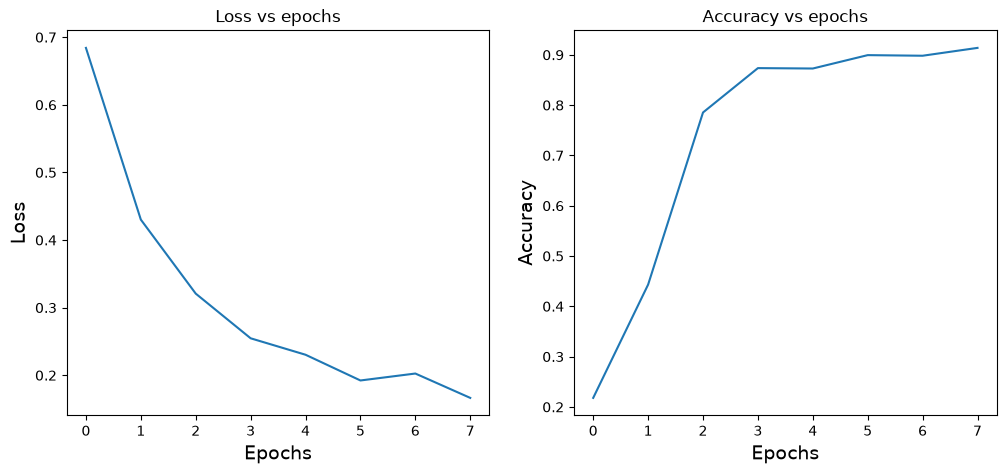

In [15]:
# Loss on the left, accuracy on the right
fig, axes = plt.subplots(1, 2, sharex=True, figsize=(12, 5))

axes[0].set_xlabel("Epochs", fontsize=14)
axes[0].set_ylabel("Loss", fontsize=14)
axes[0].set_title('Loss vs epochs')
axes[0].plot(train_loss_results)

axes[1].set_title('Accuracy vs epochs')
axes[1].set_ylabel("Accuracy", fontsize=14)
axes[1].set_xlabel("Epochs", fontsize=14)
axes[1].plot(train_accuracy_results)
plt.show()

Both curves behave as expected: the loss drops quickly during the first epochs and then flattens out, while the accuracy rises sharply up to epoch 3 (about 87%) and keeps improving slowly after that, reaching about 91% in the last epoch. The small bump in the loss at epoch 6 is normal noise from mini-batch training. The curves had not completely flattened after 8 epochs, so a longer training would probably still help on the training set.

## 8. Evaluation on the test set

The model is scored on the 10,000 test images, which it has never seen during training, going through the test dataset in batches with `training=False`.

In [19]:
# Loop over the test batches in inference mode
epoch_loss_avg = tf.keras.metrics.Mean()
epoch_accuracy = tf.keras.metrics.SparseCategoricalAccuracy()

for inputs, outputs in test_dataset:
    model_output = resnet_model(inputs, training=False)
    epoch_loss_avg(loss_obj(outputs, model_output))
    epoch_accuracy.update_state(outputs, model_output)

print("Test loss: {:.3f}".format(epoch_loss_avg.result().numpy()))
print("Test accuracy: {:.3%}".format(epoch_accuracy.result().numpy()))

Test loss: 0.661
Test accuracy: 82.760%


The model reaches a test accuracy of **82.76%** with a test loss of 0.661, against 91.38% accuracy and 0.167 loss on the training set. That gap of almost 9 points is a sign of overfitting, which is not surprising since the network was trained on just 5,000 images (less than a tenth of the dataset) and then evaluated on 10,000 different ones.

## 9. Model predictions

Four random test images, each shown next to the probability distribution the model assigns to the 10 classes and the class it finally predicts. The images are drawn at random, so they change every time the cell is run.

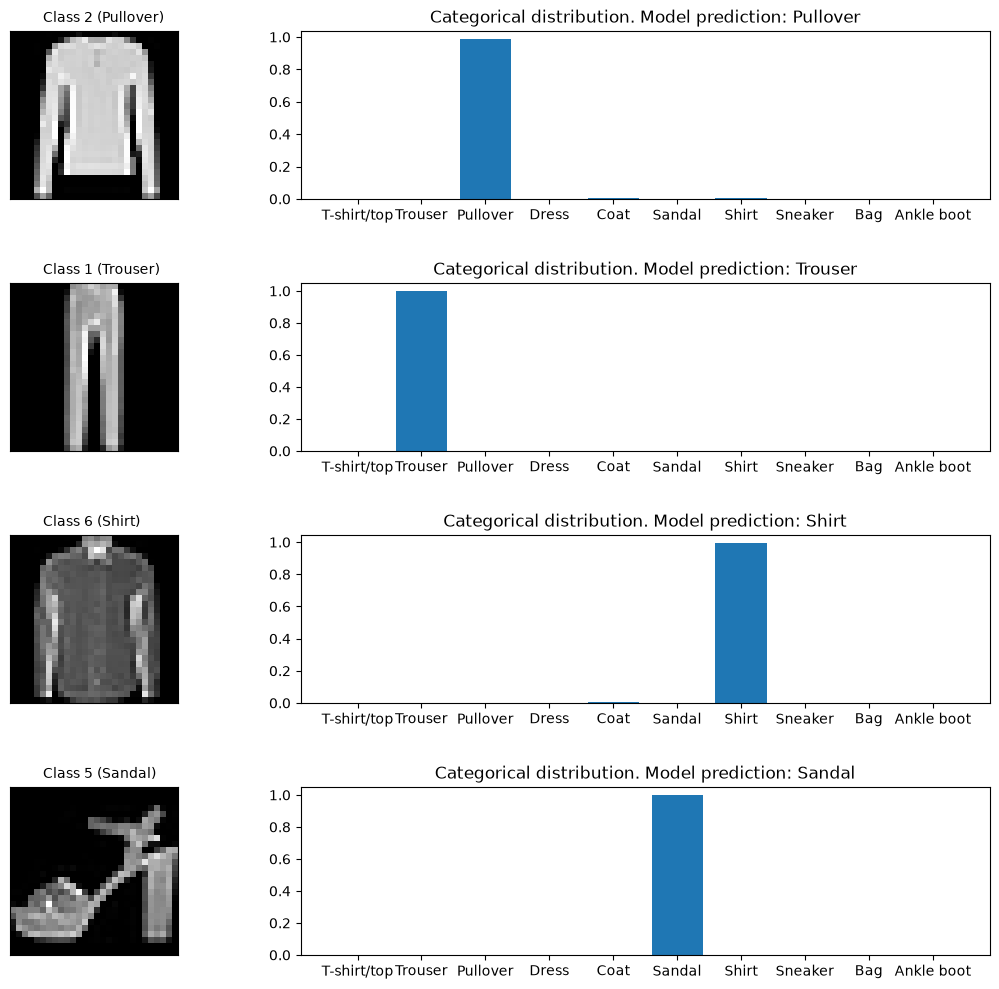

In [22]:
# Pick 4 random test images and get the model's predictions
num_test_images = test_images.shape[0]

random_inx = np.random.choice(test_images.shape[0], 4)
random_test_images = test_images[random_inx, ...]
random_test_labels = test_labels[random_inx, ...]

predictions = resnet_model(random_test_images)

# Image on the left, predicted probabilities on the right
fig, axes = plt.subplots(4, 2, figsize=(16, 12))
fig.subplots_adjust(hspace=0.5, wspace=-0.2)

for i, (prediction, image, label) in enumerate(zip(predictions, random_test_images, random_test_labels)):
    axes[i, 0].imshow(np.squeeze(image), cmap='gray')
    axes[i, 0].get_xaxis().set_visible(False)
    axes[i, 0].get_yaxis().set_visible(False)
    axes[i, 0].text(5., -2., f'Class {label} ({image_labels[label]})')
    axes[i, 1].bar(np.arange(len(prediction)), prediction)
    axes[i, 1].set_xticks(np.arange(len(prediction)))
    axes[i, 1].set_xticklabels(image_labels, rotation=0)
    pred_inx = np.argmax(prediction)
    axes[i, 1].set_title(f"Categorical distribution. Model prediction: {image_labels[pred_inx]}")

plt.show()

In this run the model classified the four random images correctly (pullover, trouser, shirt and sandal) and it was very confident in all of them, with almost all of the probability on a single class. These are relatively easy classes: with an overall accuracy of 82.76%, the mistakes are expected to concentrate in visually similar classes such as shirt, T-shirt/top, pullover and coat, which a sample this small cannot show.

## 10. Summary and results

### What was done

A residual network trained with a fully custom training loop, built only with TensorFlow 2 / Keras building blocks:

1. **Data**: Fashion-MNIST loaded through Keras, pixel values scaled to `[0, 1]`, a channel axis added to get `(28, 28, 1)` images, and batches of 32 built with `tf.data`. Only the first 5,000 of the 60,000 training images were used, together with the full 10,000-image test set.
2. **Custom layers**: a `ResidualBlock` (batch norm, ReLU, 3x3 convolution, twice, plus a skip connection) and a `FiltersChangeResidualBlock` that uses a 1x1 convolution on the shortcut so the number of channels can change. Each one was checked with a small `Sequential` model and its summary.
3. **Custom model**: a `ResNetModel` subclass of `Model` that stacks a 7x7 strided convolution, a residual block, a second strided convolution, a filter-changing residual block (64 filters) and a flatten + 10-class softmax layer.
4. **Custom training loop**: Adam (learning rate 0.001) and sparse categorical cross-entropy, with the gradients computed by `tf.GradientTape` inside a `@tf.function` and applied manually with `optimizer.apply_gradients`, for 8 epochs.
5. **Evaluation**: loss and accuracy on the 10,000 test images, plus a visual check of the probability distribution on four random test images.

### Results

| Set | Images | Loss | Accuracy |
|-----|-------:|-----:|---------:|
| Training (epoch 8) | 5,000 | 0.167 | 91.38% |
| Test | 10,000 | 0.661 | **82.76%** |

### Conclusions

- **The custom loop works.** Loss decreases and accuracy increases epoch after epoch, which confirms that the gradients from `tf.GradientTape` are correct and that `apply_gradients` is updating the weights properly, without needing `model.fit()`.
- **A small residual network learns quickly.** Reaching about 87% training accuracy in just 4 epochs on 5,000 images shows that the residual blocks train without trouble.
- **The model overfits.** Training accuracy (91.38%) is almost 9 points above test accuracy (82.76%), and the test loss (0.661) is about four times the training loss. Using only 5,000 of the 60,000 images is the most likely reason.
- **The predictions are confident.** On the random samples shown, nearly all the probability goes to one class. A confident model is not necessarily a correct one, though, so the 82.76% test accuracy is the number to trust.

### Possible improvements

- Train on the full 60,000-image training set, the simplest way to reduce the overfitting gap.
- Hold out a validation set to monitor the generalisation gap at every epoch instead of only looking at the training metrics.
- Add data augmentation (small shifts, flips) and regularisation such as dropout or weight decay.
- Build a confusion matrix to see which classes the model confuses the most (probably shirt vs. T-shirt/top vs. pullover vs. coat).